# Stage 8 — Exposure at Default (EAD) Model

## Introduction

Stages 6 and 7 produced loan-level estimates for the probability of default (PD) and the loss fraction conditional on default (LGD). The third and final component of Expected Loss is the **Exposure at Default (EAD)** — the outstanding principal balance at the moment a loan stops performing.

For revolving credit (credit cards, lines of credit), EAD is difficult to predict because borrowers often draw down credit before defaulting. For Lending Club's **installment loans**, EAD is largely mechanical: it follows the amortisation schedule. The remaining balance after *k* monthly payments is determined entirely by the original loan amount, the interest rate, and the monthly instalment. This makes EAD the most tractable of the three EL components — the analytical formula is exact, and modelling is needed only because we do not observe *when* in the loan's life a default will occur at origination.

The remaining principal balance after *k* monthly payments on an amortising loan is:

> **B(k) = loan_amnt × (1 + r)^k − installment × [(1 + r)^k − 1] / r**

where `r = int_rate / 12` is the monthly interest rate.

The **Credit Conversion Factor (CCF)** normalises this by the original balance:

> **CCF = EAD / loan_amnt**

CCF ranges from 0 (loan nearly fully repaid before default) to 1 (loan defaulted immediately). A 36-month loan that defaults at payment 18 will have a lower CCF than one that defaults at payment 3.

**Strategy:**

| Step | What | How |
|---|---|---|
| 1 | Compute **actual EAD** for historical defaults | Amortisation formula, estimating *k* from `total_pymnt` |
| 2 | Compute **actual CCF** = EAD / loan_amnt | Normalised exposure ratio |
| 3 | **Model CCF** from origination features | LightGBM regressor |
| 4 | **Score all loans**: EAD = CCF_predicted × loan_amnt | Input to Stage 9 EL formula |

> **Leakage note:** `total_pymnt` is used only to estimate *k* for computing the training target — it is never a model feature.

---

## Contents

This notebook covers:

1. **Setup** — Import libraries.
2. **Loading data** — Load defaulted loans from Stage 5 full splits.
3. **EAD computation** — Apply amortisation formula to estimate actual EAD and CCF.
4. **CCF distribution** — Explore CCF by grade, term, and payment number.
5. **CCF model** — LightGBM regressor to predict CCF at origination.
6. **Model evaluation** — Compare predicted vs actual CCF against mean baseline.
7. **EAD summary** — Save model and output EAD scores for Stage 9.

**Output:** `modeling/models/ead_model.pkl` · `data/processed/ead_scores.parquet`

**Next stage:** `09_Expected_Loss_portfolio.ipynb` — Combines PD × LGD × EAD into loan-level and portfolio-level Expected Loss estimates.

---

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
SEED = 42
print('Libraries loaded successfully.')

Libraries loaded successfully.


---

## Loading data

We load the full train/test splits (which retain all original columns) and filter to defaulted loans to compute actual EAD targets. Non-defaulted loans are scored in the EAD summary section.

In [2]:
train_full = pd.read_parquet('../data/processed/train_full.parquet')
test_full  = pd.read_parquet('../data/processed/test_full.parquet')

train_def = train_full[train_full['default'] == 1].copy()
test_def  = test_full[test_full['default']  == 1].copy()

# Normalise term to integer if stored as string (e.g. ' 36 months')
for df in [train_full, test_full, train_def, test_def]:
    if df['term'].dtype == object:
        df['term'] = df['term'].str.extract(r'(\d+)').astype(int)

print(f'Train defaults: {len(train_def):,}  |  Test defaults: {len(test_def):,}')
print(f'\nColumns available: {list(train_full.columns)}')

Train defaults: 228,052  |  Test defaults: 66,363

Columns available: ['grade', 'delinq_2yrs', 'inq_last_6mths', 'dti', 'annual_inc', 'revol_util', 'loan_amnt', 'int_rate', 'term', 'purpose', 'installment', 'total_acc', 'open_acc', 'mths_since_last_delinq', 'total_pymnt', 'default', 'ever_delinq', 'credit_history_months', 'issue_year', 'fico_score']


---

## EAD computation

For each defaulted loan we estimate the number of full payments made before default:

> **k = floor(total_pymnt / installment)**, capped at term − 1

This is an approximation — `total_pymnt` includes late fees and interest, so *k* may be slightly overstated. It is, however, the best proxy available in this dataset without a default-date field.

The amortisation balance at payment *k* is then computed analytically. For the edge case `int_rate = 0` the formula reduces to a simple linear paydown.

In [3]:
def compute_ead(df):
    """Compute EAD and CCF for a DataFrame of defaulted loans."""
    loan_amnt   = df['loan_amnt'].values.astype(float)
    installment = df['installment'].values.astype(float)
    int_rate    = df['int_rate'].values.astype(float)
    term        = df['term'].values.astype(int)
    total_pymnt = df['total_pymnt'].values.astype(float)

    # int_rate stored as percentage (e.g. 15.27 → 0.1527)
    r = np.where(int_rate > 1, int_rate / 100, int_rate) / 12

    # Payments made before default (capped at term-1)
    k = np.floor(total_pymnt / np.where(installment > 0, installment, np.inf))
    k = np.clip(k, 0, term - 1).astype(int)

    # Remaining balance
    factor = (1 + r) ** k
    ead = np.where(
        r > 0,
        loan_amnt * factor - installment * (factor - 1) / r,
        loan_amnt - installment * k
    ).clip(0, loan_amnt)

    ccf = ead / np.where(loan_amnt > 0, loan_amnt, 1)
    return ead, ccf, k

ead_train, ccf_train, k_train = compute_ead(train_def)
ead_test,  ccf_test,  k_test  = compute_ead(test_def)

print('=== EAD / CCF Summary ===')
print(f"{'':25} {'Train':>12} {'Test':>12}")
print(f"{'Mean EAD ($)':25} {ead_train.mean():>12,.0f} {ead_test.mean():>12,.0f}")
print(f"{'Mean CCF':25} {ccf_train.mean():>12.4f} {ccf_test.mean():>12.4f}")
print(f"{'Median payments (k)':25} {np.median(k_train):>12.0f} {np.median(k_test):>12.0f}")

=== EAD / CCF Summary ===
                                 Train         Test
Mean EAD ($)                     9,879       13,312
Mean CCF                        0.6164       0.8005
Median payments (k)                 19           10


---

## CCF distribution

We examine how CCF varies across loan grade, term, and payment number. The CCF distribution informs how much modelling value is achievable: if CCF is near-constant across all risk segments, a simple average is sufficient; if it varies materially by segment, a regression model adds meaningful precision.

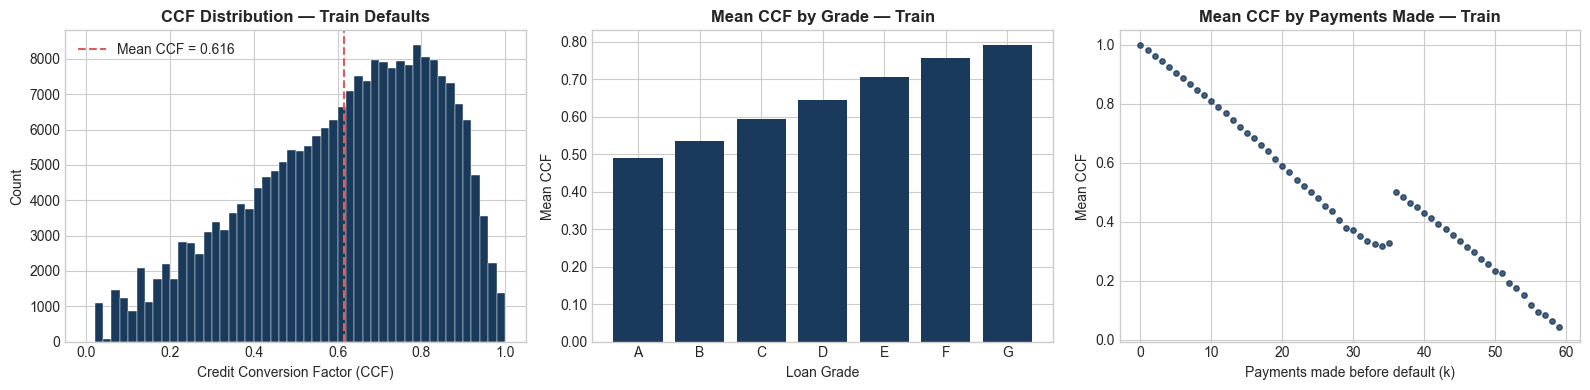

Term 36m — mean CCF: 0.5533  | median: 0.5736  | n=135,556
Term 60m — mean CCF: 0.7089  | median: 0.7426  | n=92,496


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Left: CCF histogram
ax = axes[0]
ax.hist(ccf_train, bins=50, color='#1a3a5c', edgecolor='white', linewidth=0.3)
ax.axvline(ccf_train.mean(), color='#e05c5c', linewidth=1.5,
           linestyle='--', label=f'Mean CCF = {ccf_train.mean():.3f}')
ax.set_xlabel('Credit Conversion Factor (CCF)')
ax.set_ylabel('Count')
ax.set_title('CCF Distribution — Train Defaults', fontweight='bold')
ax.legend()

# Middle: Mean CCF by grade
ax = axes[1]
tmp = train_def.copy()
tmp['ccf'] = ccf_train
grade_order = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
means = tmp.groupby('grade')['ccf'].mean().reindex(grade_order)
ax.bar(means.index, means.values, color='#1a3a5c')
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Mean CCF')
ax.set_title('Mean CCF by Grade — Train', fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.2f}'))

# Right: CCF vs payment number (k)
ax = axes[2]
k_vals = pd.Series(k_train)
ccf_s  = pd.Series(ccf_train)
avg_ccf_by_k = ccf_s.groupby(k_vals).mean().reset_index()
avg_ccf_by_k.columns = ['k', 'mean_ccf']
ax.scatter(avg_ccf_by_k['k'], avg_ccf_by_k['mean_ccf'],
           s=15, color='#1a3a5c', alpha=0.8)
ax.set_xlabel('Payments made before default (k)')
ax.set_ylabel('Mean CCF')
ax.set_title('Mean CCF by Payments Made — Train', fontweight='bold')

plt.tight_layout()
plt.savefig('../data/processed/ead_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# CCF by term
for t in [36, 60]:
    mask = train_def['term'].astype(int) == t
    print(f'Term {t:2d}m — mean CCF: {ccf_train[mask].mean():.4f}  '
          f'| median: {np.median(ccf_train[mask]):.4f}  '
          f'| n={mask.sum():,}')

---

## CCF model

We build a LightGBM regressor to predict CCF from origination features — the same feature set used in Stages 6 and 7. The model learns which loan characteristics are associated with earlier vs later defaults (and therefore higher vs lower CCF).

We compare against a mean-CCF baseline (always predict the training mean). If the regressor does not meaningfully outperform the mean, we fall back to segment averages by grade and term — a common Basel practice.

In [5]:
TARGET    = 'default'
LEAKAGE   = ['total_pymnt']
SPLIT_KEY = 'issue_year'
FEATURES  = [c for c in train_full.columns if c not in [TARGET] + LEAKAGE + [SPLIT_KEY]]

def preprocess_ead(X):
    X = X.copy()
    grade_map = {'A': 1, 'B': 2, 'C': 3, 'D': 4, 'E': 5, 'F': 6, 'G': 7}
    X['grade'] = X['grade'].map(grade_map)
    # Dummy encode purpose (14 categories)
    X = pd.get_dummies(X, columns=['purpose'], drop_first=True)
    bool_cols = X.select_dtypes(include='bool').columns
    X[bool_cols] = X[bool_cols].astype(int)
    # No missing-value handling needed for mths_since_last_delinq — Stage 1 already
    # imputed it (zero nulls), and ever_delinq already carries the delinquency signal
    return X

X_train = preprocess_ead(train_def[FEATURES])
X_test  = preprocess_ead(test_def[FEATURES])
X_test  = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train, y_test = pd.Series(ccf_train), pd.Series(ccf_test)

print(f'Train: {X_train.shape[0]:,} × {X_train.shape[1]} features')
print(f'Test:  {X_test.shape[0]:,} × {X_test.shape[1]} features')

Train: 228,052 × 29 features
Test:  66,363 × 29 features


In [6]:
ead_model = lgb.LGBMRegressor(
    n_estimators=500, learning_rate=0.05, num_leaves=63,
    random_state=SEED, n_jobs=-1, verbose=-1
)
ead_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(period=-1)]
)
print(f'Best iteration: {ead_model.best_iteration_}')

Best iteration: 28


---

## Model evaluation

We compare the LightGBM CCF model against two simpler baselines:

| Approach | Description |
|---|---|
| **Mean baseline** | Always predict the training mean CCF |
| **Segment baseline** | Mean CCF by grade × term segment |
| **LightGBM** | Full regression on origination features |

In [7]:
# Mean baseline
mean_pred = np.full(len(y_test), y_train.mean())

# Segment baseline: grade × term means from training
seg_df = train_def[['grade', 'term']].copy()
seg_df['ccf'] = ccf_train
seg_means = seg_df.groupby(['grade', 'term'])['ccf'].mean()
overall_mean = y_train.mean()

seg_pred = test_def[['grade', 'term']].apply(
    lambda r: seg_means.get((r['grade'], int(r['term'])), overall_mean), axis=1
).values

# LightGBM
lgbm_pred = ead_model.predict(X_test).clip(0, 1)

benchmarks = {
    'Mean baseline':    mean_pred,
    'Segment baseline': seg_pred,
    'LightGBM (ours)':  lgbm_pred
}

print(f"{'Model':<22} {'Test MAE':>10} {'Test RMSE':>11} {'Test R²':>9}")
print('-' * 55)
for name, pred in benchmarks.items():
    mae  = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2   = r2_score(y_test, pred)
    print(f'{name:<22} {mae:>10.4f} {rmse:>11.4f} {r2:>9.4f}')

Model                    Test MAE   Test RMSE   Test R²
-------------------------------------------------------
Mean baseline              0.2048      0.2298   -1.7908
Segment baseline           0.2045      0.2311   -1.8220
LightGBM (ours)            0.1908      0.2168   -1.4832


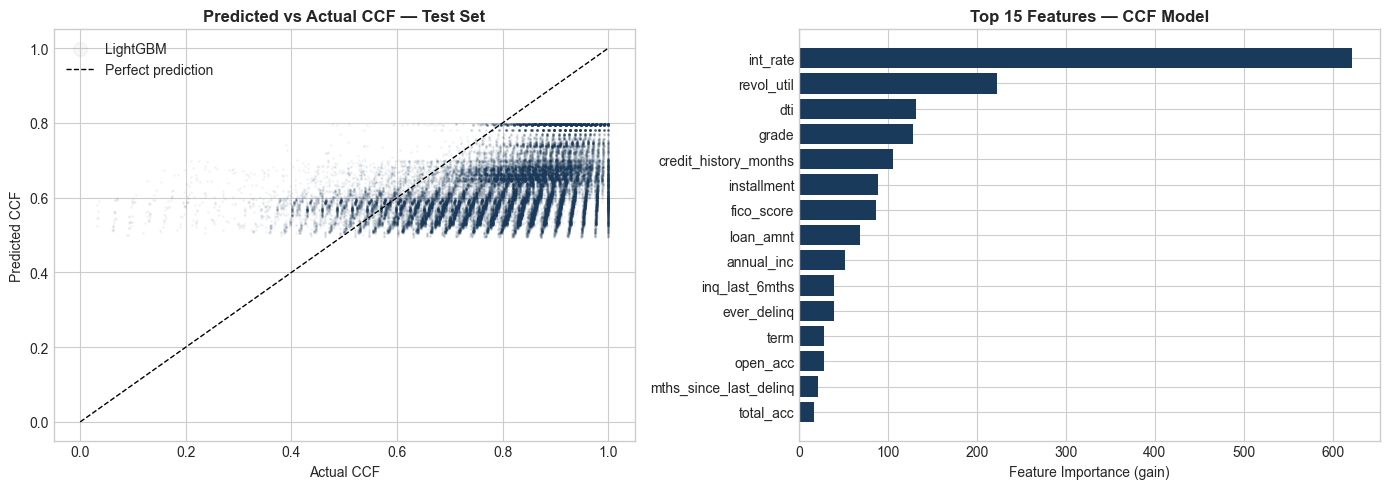

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Predicted vs Actual CCF
ax = axes[0]
ax.scatter(y_test, lgbm_pred, alpha=0.04, s=1, color='#1a3a5c', label='LightGBM')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect prediction')
ax.set_xlabel('Actual CCF')
ax.set_ylabel('Predicted CCF')
ax.set_title('Predicted vs Actual CCF — Test Set', fontweight='bold')
ax.legend(markerscale=10)

# Right: Feature importance (top 15)
ax = axes[1]
imp = pd.Series(ead_model.feature_importances_, index=X_train.columns)
imp = imp.nlargest(15).sort_values()
ax.barh(imp.index, imp.values, color='#1a3a5c')
ax.set_xlabel('Feature Importance (gain)')
ax.set_title('Top 15 Features — CCF Model', fontweight='bold')

plt.tight_layout()
plt.savefig('../data/processed/ead_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

---

## EAD summary

We save the CCF model and generate EAD scores for the full dataset. For each loan:

> **EAD = CCF_predicted × loan_amnt**

For non-defaulted loans, EAD represents the conditional exposure: "if this loan were to default, how much principal would still be outstanding?" This is the correct interpretation for Stage 9's EL formula, which applies to all loans regardless of their current status.

In [9]:
joblib.dump(ead_model, 'models/ead_model.pkl')

# Score full dataset
full_data  = pd.concat([train_full, test_full], axis=0)
X_full     = preprocess_ead(full_data[FEATURES])
X_full     = X_full.reindex(columns=X_train.columns, fill_value=0)

ccf_full   = ead_model.predict(X_full).clip(0, 1)
ead_full   = ccf_full * full_data['loan_amnt'].values

ead_scores = pd.DataFrame({
    'default':   full_data['default'].values,
    'loan_amnt': full_data['loan_amnt'].values,
    'ccf_score': ccf_full,
    'ead_score': ead_full
})
ead_scores.to_parquet('../data/processed/ead_scores.parquet', index=False)

print('EAD model saved:  modeling/models/ead_model.pkl')
print('Scores saved:     data/processed/ead_scores.parquet')
print(f'\nEAD score distribution (full dataset):')
print(ead_scores['ead_score'].describe().round(2))
print(f'\nCCF score distribution:')
print(ead_scores['ccf_score'].describe().round(4))

EAD model saved:  modeling/models/ead_model.pkl
Scores saved:     data/processed/ead_scores.parquet

EAD score distribution (full dataset):
count    1371165.00
mean        8629.44
std         5639.28
min          273.41
25%         4249.90
50%         7354.72
75%        11810.61
max        31893.78
Name: ead_score, dtype: float64

CCF score distribution:
count    1.371165e+06
mean     5.844000e-01
std      6.600000e-02
min      4.894000e-01
25%      5.327000e-01
50%      5.678000e-01
75%      6.311000e-01
max      7.973000e-01
Name: ccf_score, dtype: float64


**CCF Model Comparison:**

| Approach | Test MAE | Test RMSE | Test R² | Notes |
|---|---|---|---|---|
| Mean baseline | 0.2048 | 0.2298 | −1.7908 | Predicts train mean CCF (0.616) everywhere |
| Segment baseline | 0.2045 | 0.2311 | −1.8220 | Grade × term averages — no improvement |
| **LightGBM** | **0.1908** | **0.2168** | **−1.4832** | **Best on all metrics** |

**CCF / EAD Distribution:**

| | Train defaults | Test defaults |
|---|---|---|
| Mean CCF | 0.6164 | 0.8005 |
| Median payments (k) | 19 | 10 |
| Mean EAD ($) | $9,879 | $13,312 |

**Interpreting the results:**

The same censoring pattern seen in Stage 7 appears here. Test defaults (2017–2018) defaulted after a median of only 10 payments, leaving mean CCF at 0.80 — versus 19 payments and CCF 0.62 for training defaults. These are loans that failed quickly, with most of the principal still outstanding.

Negative R² has the same root cause as LGD: the model predicts around the training CCF distribution (≈0.62) while the test distribution sits at ≈0.80. LightGBM still reduces absolute error by **7% vs mean baseline** (MAE 0.1908 vs 0.2048).

Notice the segment baseline performs **worse** than the simple mean (R²=−1.82 vs −1.79). Grade and term alone do not explain the CCF gap — what matters is *when* the loan defaults, which is not observable at origination.

**An important implication for Stage 9:** both LGD and EAD are simultaneously high for test defaults (high CCF + high LGD = borrowed a lot, repaid very little, no recovery). This is internally consistent — fast defaults are the most destructive scenario — and means our EL estimates for 2017–2018 loans will correctly reflect elevated risk.

---

**What comes next — `09_Expected_Loss_portfolio.ipynb`**

All three EL components are now available as loan-level scores:

| Component | File | Champion | Key metric |
|---|---|---|---|
| PD | `pd_scores.parquet` | Logistic Regression | Test AUC 0.6831, KS 0.2667 |
| LGD | `lgd_scores.parquet` | LightGBM severity model | Test MAE 0.2163 |
| EAD | `ead_scores.parquet` | LightGBM CCF model | Test MAE 0.1908 |

Stage 9 combines them as **EL = PD × LGD × EAD** and builds the portfolio risk view: total expected loss by grade band, vintage, and loan purpose — the deliverable that ties the full framework together.